In [1]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'   # ajuste para o nº de núcleos do seu computador

# 05 — Modelagem (Fase 4): regressão logística

Este notebook leva o projeto da exploração (Fase 3) para a **previsão**: dado o balanço de uma empresa **fora de distress em t**, qual a chance de ela entrar em distress em t+1 e t+2? A regressão logística é o modelo principal, comparada com a baseline (Z'' de Altman) e com um desafiante não linear.

Regras que vêm dos notebooks anteriores e valem aqui:
- **O teste (t = 2021–2023) só é aberto na seção 7, uma vez**, depois de congelar modelo, variáveis, hiperparâmetros e limiar. Nada antes dela olha o teste.
- **Hiperparâmetros por validação temporal expandida dentro do treino** (notebook 04, "Riscos da escolha B"), com intervalo de 2 anos entre treino e validação, porque o alvo de t olha t+1 e t+2.
- **Nada que aprende dos dados é calculado fora do pipeline**: limites da winsorização, p99 do sem-dívida, medianas, média e desvio da padronização e coeficientes são ajustados só no treino de cada dobra (`src/modelagem.py`). Por isso aqui usamos as colunas cruas, e não as `*_w` da Fase 2.
- **Métrica principal: AUC-PR**, com AUC-ROC, Brier e recall no top 20% como apoio. Acurácia não entra: prever sempre "não" já acerta cerca de 90%.
- **Incerteza honesta**: os intervalos vêm de *bootstrap por empresa* (a mesma empresa aparece em vários anos), e a validação tem poucos eventos.

| decisão | valor aplicado aqui | situação |
|---|---|---|
| definição do alvo | `cfg.ALVO_MODELO` (B: EBITDA / desp. fin. < 1 em t+1 e t+2) | recomendação do notebook 04; **a escolha é da dupla** |
| empresas sem dívida | `fco_divida` = p99 do treino, `divida_cp_share` = 0, flag `sem_divida` | sugestão do notebook 03; **pendente** (comparada na seção 6) |
| controle de tempo | nenhum (risco relativo dentro de cada ano) | **pendente** (Selic/PIB: ver `cfg.MACRO_COLS`) |
| setor | macrossetor provisório da CVM | pendente: Subsetor Bovespa |
| divisão | treino 2010–2018, validação 2019–2020, teste 2021–2023 | decidida em 21/10/2026 |

Os **títulos dos gráficos estão neutros** de propósito: depois de ler o resultado, troque-os pela afirmação que ele sustenta (como nos notebooks 03 e 04).

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg, modelagem as mod, avaliacao as av, style

style.aplicar()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: style.num_br(x, 3))

ea = mod.carregar_base()
amostra = mod.preparar_amostra(ea)   # alvo cfg.ALVO_MODELO; amostra em risco, t de 2010 a 2023
print(f'Alvo {cfg.ALVO_MODELO}:', cfg.DEFINICOES_ALVO[cfg.ALVO_MODELO], '| base:', ea.shape, '| amostra em risco:', len(amostra))

Alvo B: ('ebitda', 2) | base: (5626, 63) | amostra em risco: 2652


## 1. Amostra e divisão temporal

A amostra é a mesma do notebook 04 para a definição escolhida: empresas **fora de distress em t** (pela mesma definição), com Y observado, sem anos anteriores ao registro na CVM e com t até 2023.

Com a DFP da CVM, a definição B passa do critério 3 do notebook 04 (151 eventos no treino, 11,6 por parâmetro), mas com folga pequena. Por isso a logística usa **regularização L2** (seção 3).

In [3]:
resumo = mod.resumo_amostra(amostra)
esperado = {'A': (188, 26, 68), 'B': (151, 17, 47)}   # eventos treino / validação / teste, notebook 04, seção 4
obtido = tuple(int(resumo.loc[s, 'eventos']) for s in ['treino', 'validacao', 'teste'])
print('eventos (treino, validação, teste):', obtido, '| notebook 04:', esperado.get(cfg.ALVO_MODELO), '(devem bater)')
resumo.style.format({'n': lambda x: style.num_br(x, 0), 'eventos': lambda x: style.num_br(x, 0), 'empresas': lambda x: style.num_br(x, 0),
                     'taxa': lambda x: style.pct_br(x, 1), 'eventos por parâmetro': lambda x: style.num_br(x, 1)}, na_rep='')

eventos (treino, validação, teste): (151, 17, 47) | notebook 04: (151, 17, 47) (devem bater)


,n,eventos,taxa,empresas,eventos por parâmetro
treino,1.571,151,"9,6%",305,"11,6"
validacao,383,17,"4,4%",226,
teste,698,47,"6,7%",279,
total,2.652,215,"8,1%",388,


**Leitura.** (i) Os eventos batem com o notebook 04: 151 no treino, 17 na validação e 47 no teste (215 no total, 8,1%). (ii) A validação tem só **17 eventos**: qualquer métrica nela é instável, e por isso ela não escolhe nada aqui, só serve de conferência. (iii) A taxa de eventos varia bastante: 9,6% no treino, 4,4% na validação e 6,7% no teste. Um modelo calibrado no treino tende a **superestimar** o risco nos anos seguintes.


## 2. Pré-processamento (dentro do pipeline)

Cada modelo é um `Pipeline` do scikit-learn com estas etapas, todas ajustadas **só no treino da dobra**:

1. **Winsorização** nos percentis 1% e 99% (mesma regra da Fase 2, `base.limites_winsor`), das seis explicativas contínuas;
2. **Regra do sem-dívida** (`cfg.REGRA_SEM_DIVIDA`): `fco_divida` recebe o teto do treino e `divida_cp_share`, 0; a flag `sem_divida` fica no modelo;
3. **Imputação pela mediana** do que ainda faltar e **padronização** (média 0, desvio 1): os coeficientes ficam por +1 desvio-padrão e a penalidade L2 trata todas as variáveis igualmente;
4. **Dummies de macrossetor**.

Não há dummies de ano: elas não existem para os anos do teste. O ciclo econômico, que o notebook 03 mostrou pesar muito (taxa de 3% a 28% por ano), fica fora do modelo, que então mede risco **relativo** entre empresas.

In [4]:
treino = amostra[amostra['split'] == 'treino'].reset_index(drop=True)
validacao = amostra[amostra['split'] == 'validacao'].reset_index(drop=True)

prep = mod.preprocessador().fit(treino[mod.colunas_entrada()], treino['Y'])
lim = pd.DataFrame(prep['winsor'].limites_, index=['p1', 'p99']).T
print('Teto de fco_divida usado para as empresas sem dívida:', style.num_br(prep['sem_divida'].teto_fco_, 2))
lim

Teto de fco_divida usado para as empresas sem dívida: 12,46


,p1,p99
alavancagem,"0,000","0,710"
divida_cp_share,"0,011","1,000"
roa,"-0,058","0,331"
liquidez,"0,001","8,080"
fco_divida,"-0,909","12,462"
log_ativo,"9,863","18,973"


In [5]:
# O que o modelo enxerga no treino: média 0 e desvio 1 nas contínuas; flag e dummies em 0/1
prep.transform(treino[mod.colunas_entrada()]).describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
alavancagem,"-0,000","1,000","-1,546","2,495"
divida_cp_share,"0,000","1,000","-1,219","2,831"
roa,"-0,000","1,000","-1,934","4,326"
liquidez,"-0,000","1,000","-0,545","7,557"
fco_divida,"0,000","1,000","-0,699","2,963"
log_ativo,"0,000","1,000","-2,706","2,341"
sem_divida,"0,080","0,272","0,000","1,000"
setor_Bens industriais,"0,151","0,358","0,000","1,000"
setor_Comunicações e TI,"0,060","0,237","0,000","1,000"
setor_Construção e imobiliário,"0,113","0,317","0,000","1,000"


## 3. Escolha de C por validação temporal expandida

`C` é o inverso da regularização L2: quanto **menor**, mais os coeficientes são encolhidos em direção a zero, o que protege contra o excesso de parâmetros para poucos eventos.

Cada dobra valida em **um ano** do treino (2015–2018) e treina com os anos até `v − 3`. O intervalo de 2 anos existe porque o rótulo de t usa t+1 e t+2: com ele, nenhum rótulo de treino usa informação do ano de validação. Dobras com poucos eventos no treino (`cfg.MIN_EVENTOS_DOBRA`) são descartadas.

Escolha de `C` (`cfg.REGRA_C`): por padrão, o `C` de **maior AUC-PR** fora da amostra (`'max'`). A alternativa `'1ep'` é a regra clássica de parcimônia (o `C` mais regularizado a até 1 erro-padrão do melhor, com erro-padrão por *bootstrap por empresa*), mas **cuidado**: AUC-PR e AUC-ROC só olham o ranking, e encolher os coeficientes quase não piora o ranking. A curva fica plana e a regra de 1 EP tende a escorregar para a ponta mais regularizada da grade, que é um modelo quase nulo. Use-a só se a curva tiver um formato claro.

In [6]:
dobras, descartadas = mod.dobras_temporais(treino)
pd.DataFrame([{'ano de validação': v, 'treino: t até': treino.loc[tr, 'ano'].max(), 'n treino': len(tr),
               'eventos treino': int(treino.loc[tr, 'Y'].sum()), 'n validação': len(va),
               'eventos validação': int(treino.loc[va, 'Y'].sum())} for tr, va, v in dobras])
if descartadas:
    print('Dobras descartadas (ano, eventos no treino, eventos na validação):', descartadas)

In [7]:
res = mod.ajuste_completo(amostra)   # logística L2, pesos balanceados, setor, regra p99/0
tabC = res['tabela_C']
print(f"C escolhido: {res['C']} | regra: {cfg.REGRA_C} | erro-padrão da AUC-PR: {style.num_br(tabC.attrs['ep'], 3)} | "
      f"limiar (F{cfg.BETA_LIMIAR:g}, previsões fora da amostra): {style.num_br(res['limiar'], 3)}")
tabC

C escolhido: 3.0 | regra: max | erro-padrão da AUC-PR: 0,047 | limiar (F2, previsões fora da amostra): 0,518


,C,AUC-PR,AUC-ROC,Brier,AUC-PR por dobra (média),melhor,escolhido
0,"0,001","0,143","0,656","0,242","0,175",False,False
1,"0,003","0,141","0,650","0,234","0,174",False,False
2,"0,010","0,145","0,647","0,225","0,173",False,False
3,"0,030","0,159","0,650","0,219","0,194",False,False
4,"0,100","0,179","0,655","0,216","0,205",False,False
5,"0,300","0,188","0,657","0,214","0,209",False,False
6,"1,000","0,216","0,659","0,214","0,214",False,False
7,"3,000","0,221","0,662","0,215","0,216",True,True
8,"10,000","0,214","0,664","0,215","0,211",False,False
9,"30,000","0,196","0,664","0,215","0,202",False,False


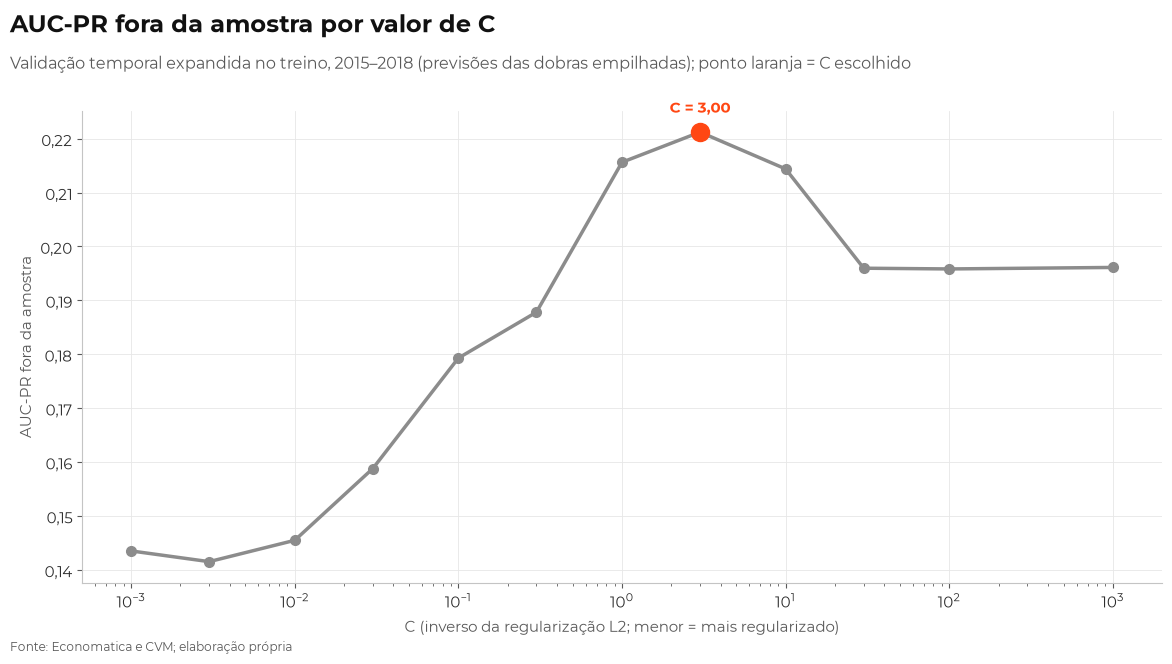

In [8]:
fig, ax = av.fig_selecao_c(tabC, res['C'])
style.titulos(fig, 'AUC-PR fora da amostra por valor de C',
              'Validação temporal expandida no treino, 2015–2018 (previsões das dobras empilhadas); ponto laranja = C escolhido')
style.salvar(fig, 'fig17_selecao_c')
plt.show()

**Leitura.** (i) O `C` escolhido para a logística principal é **3**, longe das bordas da grade. Os avisos de borda (C = 1.000) vêm de variantes da seção 6 (sem pesos, sem setor), em que a regularização quase não muda nada. (ii) A curva é **plana**: de C = 0,3 a C = 1.000, a AUC-PR fora da amostra fica entre 0,19 e 0,22, dentro de um erro-padrão (0,047). A escolha de `C` pesa pouco na conclusão. (iii) A AUC-PR fora da amostra (0,22) fica bem acima da taxa de eventos do treino (9,6%): há sinal nos indicadores.


## 4. Modelos na validação (2019–2020)

Comparamos, ajustados no treino:
- **Z'' (baseline)**: o Z''-score de Altman para emergentes, recalibrado por uma logística de uma variável. A ordenação (AUC-PR e AUC-ROC) é a do próprio Z'';
- **Logística L2 com pesos de classe balanceados** (modelo principal): melhora o recall, mas **infla as probabilidades**;
- **Logística L2 sem pesos**: probabilidades calibradas, importantes para o Brier;
- **Logística com splines** em alavancagem e tamanho (o notebook 03 viu limiar na alavancagem e U no tamanho);
- **Gradient boosting raso** (desafiante não linear, hiperparâmetros fixos);
- **Random forest** com árvores rasas (segundo desafiante não linear, hiperparâmetros fixos).

O **limiar** de cada modelo maximiza o F2 (privilegia o recall) nas previsões fora da amostra das dobras do treino. A validação **não** é usada para escolher nada.

> **Brier:** só compare entre modelos calibrados (Z'' e logística sem pesos). Com `class_weight='balanced'` as probabilidades saem infladas por construção, e o Brier piora sem que o ranking piore.

In [9]:
res_sp = mod.ajuste_completo(amostra, class_weight=None)
res_spl = mod.ajuste_completo(amostra, splines=True)
z = mod.ajuste_fixo(mod.pipeline_z, treino, dobras)
gb = mod.ajuste_fixo(mod.pipeline_gb, treino, dobras)
rf = mod.ajuste_fixo(mod.pipeline_rf, treino, dobras)

modelos = {"Z'' (baseline)": z,
           'Logística L2 (pesos balanceados)': res,
           'Logística L2 (sem pesos)': res_sp,
           'Logística com splines': res_spl,
           'Gradient boosting (desafiante)': gb,
           'Random forest (desafiante)': rf}
PRINCIPAL = 'Logística L2 (pesos balanceados)'
limiares = {k: v['limiar'] for k, v in modelos.items()}

prev_val = {k: mod.prever(v['modelo'], validacao) for k, v in modelos.items()}
av.tabela_metricas(validacao['Y'], prev_val, limiares)

C:\Users\mitsu\OneDrive\Documentos\GitHub\Projeto-2_CB\src\modelagem.py:262: UserWarning: C escolhido (1000.0) está na borda da grade: estenda cfg.GRADE_C nessa direção.
  warnings.warn(f'C escolhido ({c_esc}) está na borda da grade: estenda cfg.GRADE_C nessa direção.')


,n,eventos,taxa,AUC-PR,AUC-ROC,Brier,recall top 20%,limiar,marcados,precisão,recall,F2
Z'' (baseline),383,17,"0,044","0,103","0,563","0,045","0,294","0,073",377,"0,040","0,882","0,169"
Logística L2 (pesos balanceados),383,17,"0,044","0,059","0,555","0,205","0,176","0,518",98,"0,041","0,235","0,120"
Logística L2 (sem pesos),383,17,"0,044","0,061","0,539","0,046","0,176","0,105",88,"0,045","0,235","0,128"
Logística com splines,383,17,"0,044","0,049","0,536","0,207","0,118","0,412",162,"0,049","0,471","0,174"
Gradient boosting (desafiante),383,17,"0,044","0,082","0,690","0,148","0,294","0,404",122,"0,082","0,588","0,263"
Random forest (desafiante),383,17,"0,044","0,127","0,677","0,148","0,235","0,449",98,"0,061","0,353","0,181"


**Leitura.** Na validação (17 eventos), a logística **não** supera o Z'': AUC-PR de 0,059 contra 0,103, e AUC-ROC de 0,56 contra 0,56. O random forest tem a maior AUC-PR (0,127), e o gradient boosting, a maior AUC-ROC (0,69). Com 17 eventos, essas diferenças não são evidência, mas são um primeiro aviso: a vantagem da logística no treino pode não se repetir fora dele. O limiar do Z'' marca 377 de 383 empresas, ou seja, não serve como regra de corte.


## 5. Inferência: as hipóteses H1–H4 (treino)

O estudo é de **associação**. Para testar as hipóteses ajustamos a logística **sem penalização** no treino, com **erro-padrão robusto agrupado por empresa** (o painel repete a mesma empresa em vários anos, então o erro-padrão comum seria otimista). Intervalos de 90%.

Como ler:
- razão de chances **por +1 desvio-padrão** da variável (winsorizada), controlando pelas demais e pelo setor;
- **confirma** = sinal esperado e p < 0,10. "Sinal certo, não significativo" **não** é confirmação;
- para a inferência usamos `regra='nenhuma'` (mediana) no sem-dívida: com uma constante mais a flag, o ajuste é o mesmo, mas só a mediana deixa o coeficiente de `sem_divida` legível ("sem dívida" contra uma empresa com dívida típica). Com o p99, a razão de chances da flag só desfaz o valor imputado e perde o sentido;
- coeficientes provavelmente **atenuados** pelo viés de sobrevivência (README).

In [10]:
Xi = mod.matriz_inferencia(treino)
coefs = mod.logit_agrupado(Xi, treino['Y'], treino['ticker'])
print(f"N = {coefs.attrs['N']} empresa-anos | {coefs.attrs['empresas']} empresas (clusters) | setor de referência: {Xi.attrs['setor_referencia']}")
hip = mod.tabela_hipoteses(coefs)
hip[['hipótese', 'sinal esperado', 'sinal estimado', 'odds_ratio', 'or_inf', 'or_sup', 'p', 'veredito']]

N = 1571 empresa-anos | 305 empresas (clusters) | setor de referência: Consumo cíclico


,hipótese,sinal esperado,sinal estimado,odds_ratio,or_inf,or_sup,p,veredito
variável,,,,,,,,
alavancagem,H1,+,+,"1,423","1,122","1,805","0,015",confirma
divida_cp_share,H1,+,+,"1,417","1,149","1,747","0,006",confirma
roa,H2,−,−,"0,935","0,758","1,153","0,599","sinal certo, não significativo"
liquidez,H3,−,+,"1,005","0,839","1,204","0,965","sinal oposto, não significativo"
fco_divida,H4,−,−,"0,548","0,197","1,526","0,334","sinal certo, não significativo"
log_ativo,controle,—,−,"0,734","0,599","0,901","0,013",controle


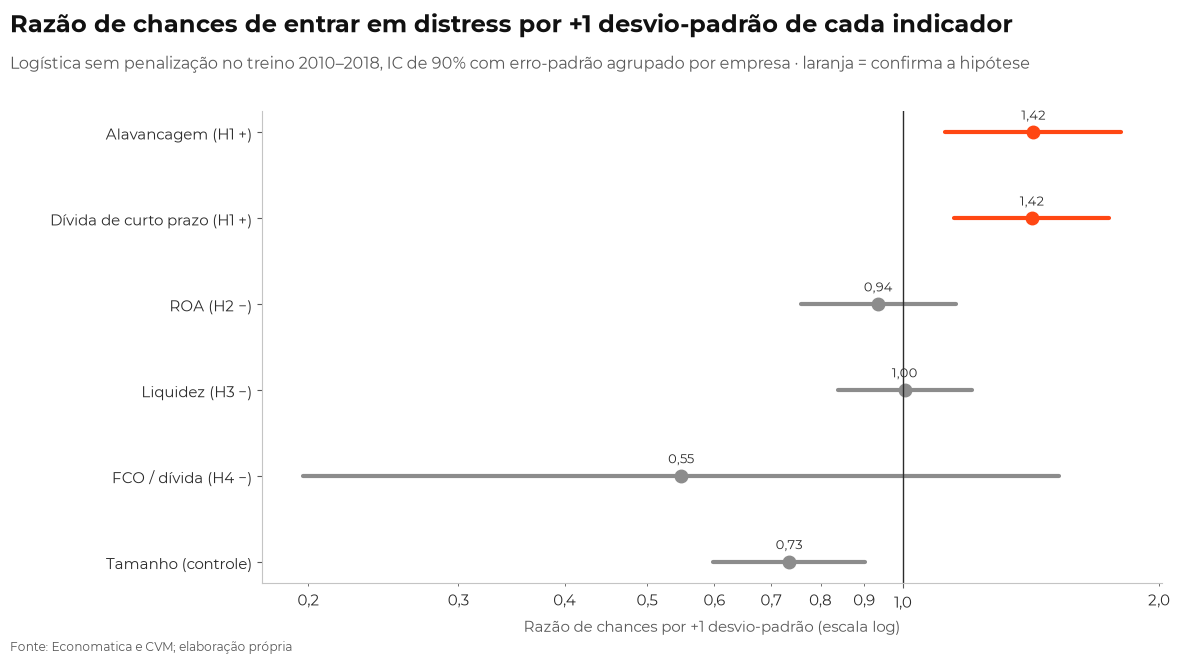

,coef,ep,z,p,odds_ratio,or_inf,or_sup
const,"-2,568","0,254","-10,103","0,000","0,077","0,050","0,116"
alavancagem,"0,353","0,145","2,439","0,015","1,423","1,122","1,805"
divida_cp_share,"0,348","0,128","2,731","0,006","1,417","1,149","1,747"
roa,"-0,067","0,127","-0,526","0,599","0,935","0,758","1,153"
liquidez,"0,005","0,110","0,043","0,965","1,005","0,839","1,204"
fco_divida,"-0,601","0,622","-0,966","0,334","0,548","0,197","1,526"
log_ativo,"-0,309","0,124","-2,482","0,013","0,734","0,599","0,901"
sem_divida,"0,393","0,524","0,751","0,453","1,482","0,626","3,507"
setor_Bens industriais,"-0,278","0,361","-0,769","0,442","0,757","0,418","1,372"
setor_Comunicações e TI,"-0,276","0,531","-0,520","0,603","0,759","0,317","1,817"


In [11]:
fig, ax = av.fig_coeficientes(hip)
style.titulos(fig, 'Razão de chances de entrar em distress por +1 desvio-padrão de cada indicador',
              'Logística sem penalização no treino 2010–2018, IC de 90% com erro-padrão agrupado por empresa · laranja = confirma a hipótese')
fig.subplots_adjust(left=0.22)
style.salvar(fig, 'fig18_coeficientes')
plt.show()
coefs   # inclui constante, flag e dummies de setor

**Leitura.**
- **H1 confirma nas duas medidas:** +1 desvio-padrão de alavancagem eleva as chances em 42% (p = 0,02), e de dívida de curto prazo, também em 42% (p = 0,006). No notebook 03, a alavancagem tinha formato de U no bivariado; controlando pelas demais, o efeito linear aparece.
- **H2 (ROA) e H4 (FCO/dívida) têm o sinal certo, mas sem significância** (p = 0,60 e 0,33). No bivariado eram os padrões mais fortes, e o efeito some ou fica impreciso quando se controla pela dívida e pelo tamanho. O intervalo do FCO/dívida é muito largo (razão de chances de 0,20 a 1,53).
- **H3 (liquidez):** sem efeito (razão de chances 1,00, p = 0,97).
- **Tamanho** reduz o risco (−27%, p = 0,01), e construção e imobiliário é o único setor que difere da referência (p = 0,05).


## 5b. Regressão de referência: modelo linear de probabilidade (treino)

O mesmo desenho da seção 5 (mesmas variáveis padronizadas, setor, erro-padrão agrupado por empresa), estimado por **MQO**. Os coeficientes viram **pontos percentuais** de probabilidade por +1 desvio-padrão, mais fáceis de ler que a razão de chances. O custo conhecido: probabilidades ajustadas podem sair **abaixo de zero**, e por isso a logística continua sendo o modelo principal. O gráfico de resíduos por faixa compara os dois: perto de zero, o modelo não erra de forma sistemática.

In [12]:
lpm = mod.mqo_agrupado(Xi, treino['Y'], treino['ticker'])
cont = list(cfg.EXPLICATIVAS)
ef = lpm.loc[cont, ['coef', 'ep', 'p']].copy()
ef['efeito (p.p.)'] = 100 * ef['coef']
ef['hipótese'] = [cfg.EXPLICATIVAS[v][0] for v in cont]
corr = np.corrcoef(Xi.to_numpy(dtype=float), rowvar=False)
vif = pd.Series(np.diag(np.linalg.pinv(corr)), index=Xi.columns)
print(f"N = {lpm.attrs['N']} | R² = {style.pct_br(lpm.attrs['R2'], 1)} | ajustados < 0: {style.pct_br(lpm.attrs['frac_negativos'], 1)}"
      f" | taxa média no treino: {style.pct_br(treino['Y'].mean(), 1)} | VIF máximo: {style.num_br(vif.max(), 2)} ({vif.idxmax()})")
ef[['hipótese', 'efeito (p.p.)', 'p']]

N = 1571 | R² = 4,4% | ajustados < 0: 4,9% | taxa média no treino: 9,6% | VIF máximo: 1,90 (alavancagem)


,hipótese,efeito (p.p.),p
alavancagem,H1,"3,262","0,014"
divida_cp_share,H1,"3,284","0,008"
roa,H2,"-0,579","0,599"
liquidez,H3,"-0,067","0,934"
fco_divida,H4,"-2,119","0,013"
log_ativo,controle,"-2,956","0,005"


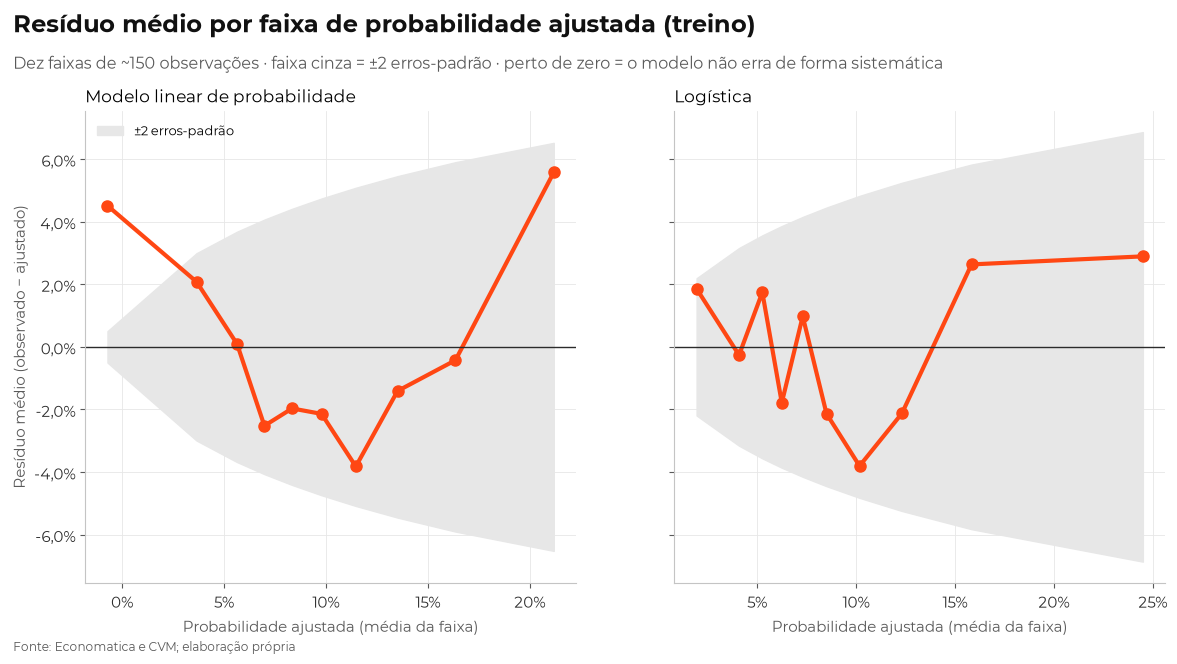

faixas dentro de ±2 EP: linear 9 de 10 | logística 10 de 10


In [13]:
res_lpm = mod.residuos_por_faixa(treino['Y'], lpm.attrs['ajustados'])
res_log = mod.residuos_por_faixa(treino['Y'], mod.prob_logit(coefs, Xi))
fig, axs = av.fig_residuos({'Modelo linear de probabilidade': res_lpm, 'Logística': res_log})
style.titulos(fig, 'Resíduo médio por faixa de probabilidade ajustada (treino)',
              'Dez faixas de ~150 observações · faixa cinza = ±2 erros-padrão · perto de zero = o modelo não erra de forma sistemática')
style.salvar(fig, 'fig23_residuos_lpm_logit')
plt.show()
dentro = lambda r: int((r['residuo'].abs() <= 2 * r['ep']).sum())
print(f'faixas dentro de ±2 EP: linear {dentro(res_lpm)} de 10 | logística {dentro(res_log)} de 10')

**Leitura.** No modelo linear, H1 se confirma como na logística (+3,3 p.p. de alavancagem e +3,3 p.p. de dívida de curto prazo), e **H4 também** (−2,1 p.p. de FCO/dívida, p = 0,01), ao contrário da logística. H2 e H3 não se confirmam. O R² é de 4,4%, como esperado para um alvo raro, e 4,9% das probabilidades ajustadas ficam abaixo de zero, a limitação conhecida do modelo linear. Nos resíduos por faixa, a logística fica dentro da banda de ±2 erros-padrão nas 10 faixas, e o modelo linear em 9 (erra nas pontas). Por isso a logística continua sendo o modelo principal.


## 5c. Regressão × machine learning: importância por permutação (treino)

Os modelos concordam sobre **quais** variáveis importam? Em cada dobra da validação temporal do treino (as mesmas da seção 3), ajustamos o modelo no treino da dobra e embaralhamos **uma variável de cada vez** na validação da dobra, 10 vezes; a importância é a **queda da AUC-ROC** (média das dobras e das repetições). Usamos a AUC-ROC porque, com 10 a 30 eventos por dobra, a AUC-PR oscila demais. Queda negativa = embaralhar a variável **melhora** o modelo: ela não ajuda fora da amostra. O teste não é usado.

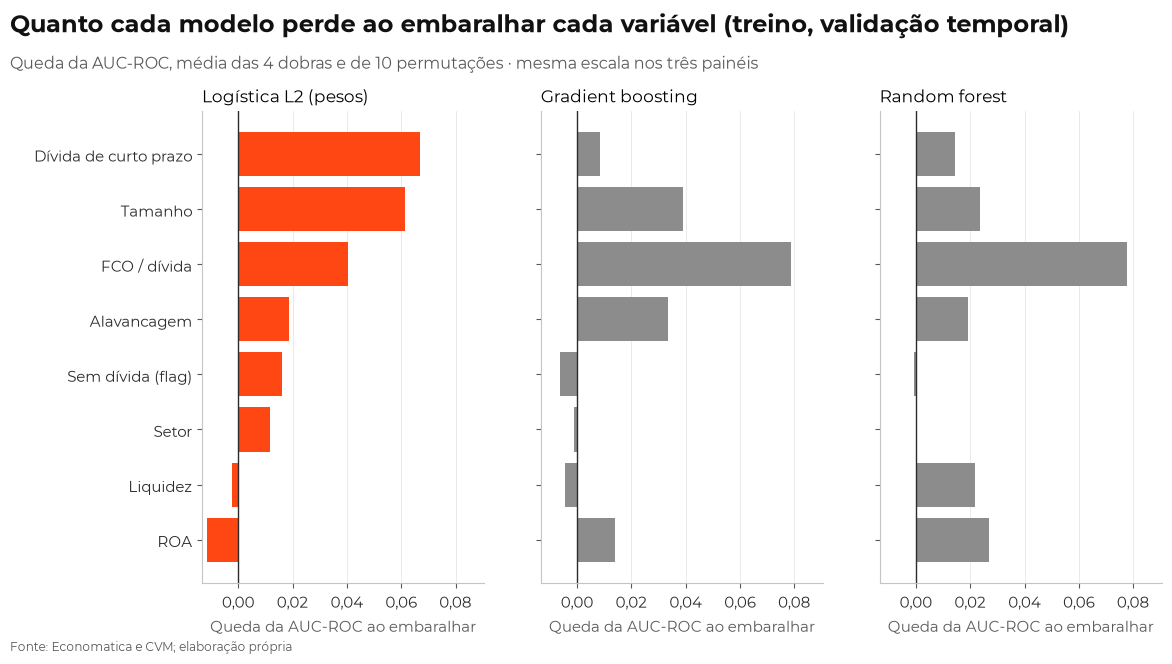

modelo,Logística L2 (pesos),Gradient boosting,Random forest,posição (Logística L2 (pesos)),posição (Gradient boosting),posição (Random forest)
variável,,,,,,
divida_cp_share,"0,067","0,009","0,014",1,5,6
log_ativo,"0,061","0,039","0,024",2,2,3
fco_divida,"0,040","0,079","0,078",3,1,1
alavancagem,"0,019","0,033","0,019",4,3,5
sem_divida,"0,016","-0,006","-0,001",5,8,8
setor,"0,012","-0,001","-0,000",6,6,7
liquidez,"-0,002","-0,005","0,022",7,7,4
roa,"-0,012","0,014","0,027",8,4,2


In [14]:
fabricas = {'Logística L2 (pesos)': lambda: mod.pipeline_logit(res['C']),
            'Gradient boosting': mod.pipeline_gb,
            'Random forest': mod.pipeline_rf}
imp = mod.importancia_permutacao(fabricas, treino, dobras, n_rep=10)
fig, axs = av.fig_importancia(imp, destaque='Logística L2 (pesos)')
style.titulos(fig, 'Quanto cada modelo perde ao embaralhar cada variável (treino, validação temporal)',
              f'Queda da AUC-ROC, média das {len(dobras)} dobras e de 10 permutações · mesma escala nos três painéis')
fig.subplots_adjust(left=0.17)
style.salvar(fig, 'fig22_importancia_permutacao')
plt.show()
imp.sort_values(imp.columns[0], ascending=False).assign(**{f'posição ({c})': imp[c].rank(ascending=False).astype(int) for c in imp.columns})

**Leitura.** Os modelos concordam **em parte**. FCO/dívida é a variável mais importante nas duas árvores e a 3ª na logística; o tamanho fica entre as três primeiras nos três modelos. A dívida de curto prazo é a 1ª na logística, mas só a 5ª e a 6ª nas árvores. ROA e liquidez têm importância negativa na logística (embaralhar não piora) e positiva no random forest, o que sugere efeitos não lineares. A flag sem dívida fica em último nas duas árvores: não ajuda fora da amostra. A ordem é indicativa, com 10 a 30 eventos por dobra.


## 6. Decisões pendentes: o que os dados dizem

Cada linha refaz **todo** o pipeline (escolha de C no treino incluída) com uma variante das decisões em aberto. A comparação é pela **AUC-PR fora da amostra no treino** (validação temporal), nunca pelo teste. Se as diferenças ficam dentro do erro-padrão, os dados não distinguem as opções: escolha a mais simples ou a mais defensável.

In [15]:
variantes = {
    'principal (p99 e 0 no sem-dívida, com setor, linear, pesos)': res,
    'sem-dívida: sem regra especial (mediana + flag)': mod.ajuste_completo(amostra, regra='nenhuma'),
    'sem controle de setor': mod.ajuste_completo(amostra, usar_setor=False),
    'com splines em alavancagem e tamanho': res_spl,
    'sem pesos de classe': res_sp,
}
linhas = []
for nome, r in variantes.items():
    t = r['tabela_C']
    e = t[t['escolhido']].iloc[0]
    linhas.append({'variante': nome, 'C': e['C'], 'AUC-PR (CV)': e['AUC-PR'], 'AUC-ROC (CV)': e['AUC-ROC'],
                   'Brier (CV)': e['Brier'], 'EP da AUC-PR': t.attrs['ep']})
pd.DataFrame(linhas).set_index('variante')

C:\Users\mitsu\OneDrive\Documentos\GitHub\Projeto-2_CB\src\modelagem.py:262: UserWarning: C escolhido (1000.0) está na borda da grade: estenda cfg.GRADE_C nessa direção.
  warnings.warn(f'C escolhido ({c_esc}) está na borda da grade: estenda cfg.GRADE_C nessa direção.')


,C,AUC-PR (CV),AUC-ROC (CV),Brier (CV),EP da AUC-PR
variante,,,,,
"principal (p99 e 0 no sem-dívida, com setor, linear, pesos)","3,000","0,221","0,662","0,215","0,047"
sem-dívida: sem regra especial (mediana + flag),"0,100","0,200","0,684","0,211","0,048"
sem controle de setor,"1.000,000","0,169","0,670","0,218","0,043"
com splines em alavancagem e tamanho,"10,000","0,261","0,719","0,211","0,048"
sem pesos de classe,"1.000,000","0,191","0,670","0,069","0,045"


**Leitura.** Todas as diferenças ficam dentro de cerca de 1 erro-padrão (0,047), então os dados distinguem pouco as opções. (i) **Sem-dívida:** a regra p99 + 0 dá 0,221, contra 0,200 da mediana + flag; mantemos a regra p99. (ii) **Setor:** tirar o setor piora a AUC-PR fora da amostra (0,169 contra 0,221), então ele fica, mesmo provisório. (iii) **Splines:** são a melhor variante (0,261), mas a diferença é menor que 1 erro-padrão, e a versão linear é a que permite ler as hipóteses; ficam como variante. (iv) **Pesos de classe:** sem eles a AUC-PR cai para 0,191; o ranking muda pouco, e o Brier não é comparável.


## 7. Teste (t = 2021–2023): abrir **uma vez**

Antes de rodar esta seção, o que está **congelado**: alvo (`cfg.ALVO_MODELO`), variáveis, regras de pré-processamento, `C` de cada logística (escolhido na seção 3) e limiar de cada modelo (previsões fora da amostra no treino). Se algo mudar depois de ver o teste, a avaliação deixa de ser independente: registre a mudança como análise exploratória.

O modelo é ajustado **só com o treino (2010–2018)**, e não com treino + validação. O motivo é o intervalo: o rótulo de t = 2019–2020 usa os anos 2021–2022, que são anos do teste. Treinar com eles seria usar o futuro do teste.

Intervalos de 90% por *bootstrap por empresa*; a pergunta central é se a logística supera a baseline Z'', então comparamos **diferenças** na mesma reamostragem.

In [16]:
teste = amostra[amostra['split'] == 'teste'].reset_index(drop=True)
prev_te = {k: mod.prever(v['modelo'], teste) for k, v in modelos.items()}
av.tabela_metricas(teste['Y'], prev_te, limiares)

,n,eventos,taxa,AUC-PR,AUC-ROC,Brier,recall top 20%,limiar,marcados,precisão,recall,F2
Z'' (baseline),698,47,"0,067","0,181","0,610","0,064","0,447","0,073",692,"0,065","0,957","0,256"
Logística L2 (pesos balanceados),698,47,"0,067","0,107","0,639","0,192","0,383","0,518",148,"0,122","0,383","0,268"
Logística L2 (sem pesos),698,47,"0,067","0,115","0,639","0,063","0,383","0,105",146,"0,130","0,404","0,284"
Logística com splines,698,47,"0,067","0,112","0,654","0,190","0,404","0,412",282,"0,103","0,617","0,309"
Gradient boosting (desafiante),698,47,"0,067","0,115","0,706","0,155","0,340","0,404",225,"0,129","0,617","0,351"
Random forest (desafiante),698,47,"0,067","0,131","0,740","0,152","0,426","0,449",190,"0,132","0,532","0,331"


In [17]:
p = prev_te[PRINCIPAL]
marcado = p >= limiares[PRINCIPAL]
cm = pd.crosstab(pd.Series(np.where(teste['Y'] == 1, 'entrou em distress', 'não entrou'), name='real'),
                 pd.Series(np.where(marcado, 'marcada como risco', 'não marcada'), name=f'{PRINCIPAL}, no limiar'))
cm

"Logística L2 (pesos balanceados), no limiar",marcada como risco,não marcada
real,,
entrou em distress,18,29
não entrou,130,521


In [18]:
resumo_boot, difs = av.bootstrap_empresas(teste['Y'], prev_te, teste['ticker'], referencia="Z'' (baseline)")
difs

,modelo,métrica,diferença mediana,ic_inf,ic_sup,P(> Z'' (baseline))
0,Logística L2 (pesos balanceados),AUC-PR,"-0,075","-0,189","-0,003","0,038"
1,Logística L2 (pesos balanceados),AUC-ROC,"0,024","-0,076","0,129","0,644"
2,Logística L2 (sem pesos),AUC-PR,"-0,066","-0,184","0,014","0,092"
3,Logística L2 (sem pesos),AUC-ROC,"0,024","-0,087","0,141","0,642"
4,Logística com splines,AUC-PR,"-0,069","-0,180","0,004","0,061"
5,Logística com splines,AUC-ROC,"0,036","-0,053","0,137","0,758"
6,Gradient boosting (desafiante),AUC-PR,"-0,070","-0,183","0,004","0,069"
7,Gradient boosting (desafiante),AUC-ROC,"0,091","-0,009","0,194","0,930"
8,Random forest (desafiante),AUC-PR,"-0,053","-0,164","0,027","0,150"
9,Random forest (desafiante),AUC-ROC,"0,123","0,026","0,229","0,978"


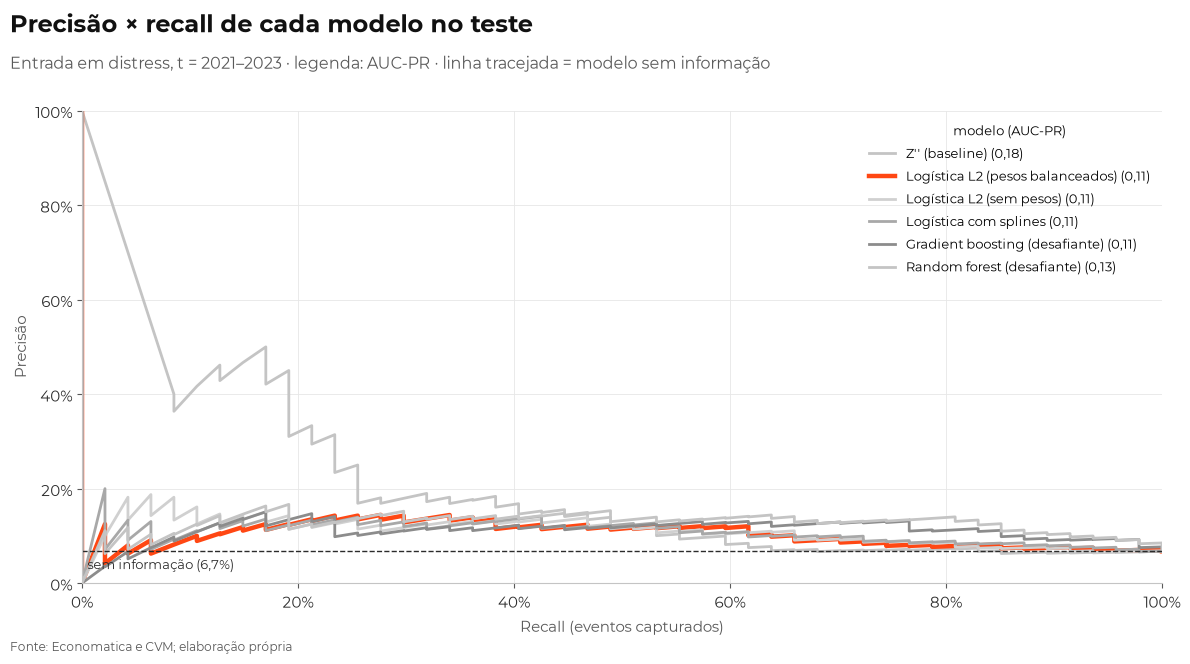

In [19]:
fig, ax = av.fig_pr(teste['Y'], prev_te, PRINCIPAL)
style.titulos(fig, 'Precisão × recall de cada modelo no teste',
              'Entrada em distress, t = 2021–2023 · legenda: AUC-PR · linha tracejada = modelo sem informação')
style.salvar(fig, 'fig19_precisao_recall_teste')
plt.show()

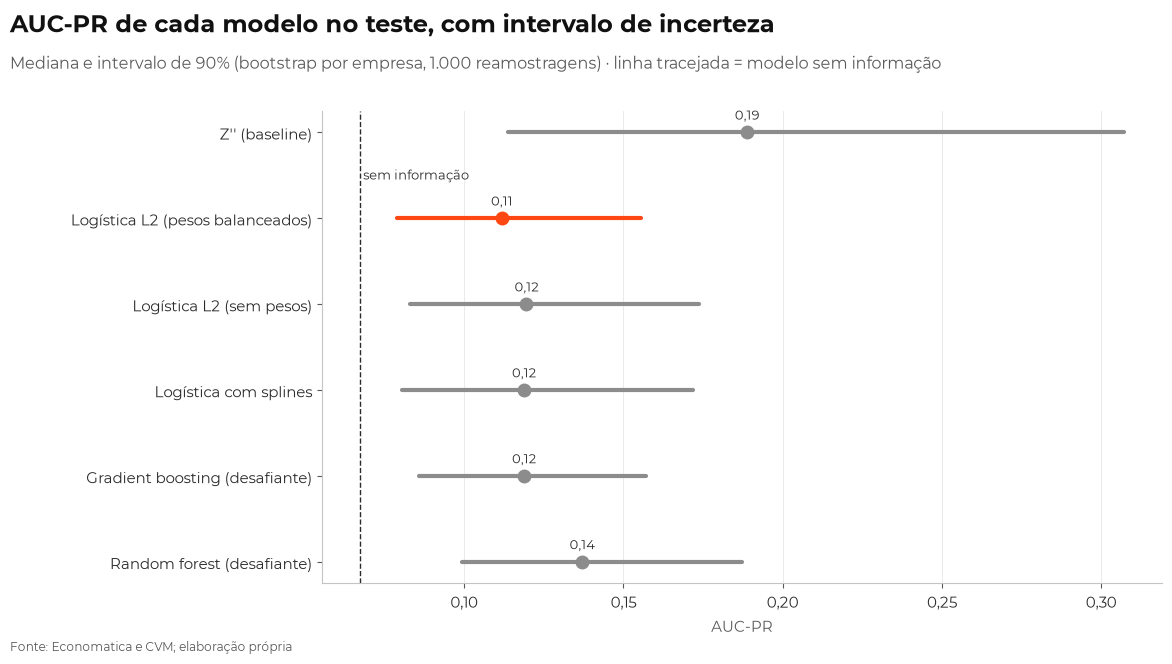

,modelo,métrica,mediana,ic_inf,ic_sup
0,Z'' (baseline),AUC-PR,"0,189","0,114","0,307"
1,Z'' (baseline),AUC-ROC,"0,615","0,523","0,702"
2,Logística L2 (pesos balanceados),AUC-PR,"0,112","0,079","0,155"
3,Logística L2 (pesos balanceados),AUC-ROC,"0,640","0,565","0,708"
4,Logística L2 (sem pesos),AUC-PR,"0,120","0,083","0,174"
5,Logística L2 (sem pesos),AUC-ROC,"0,641","0,565","0,712"
6,Logística com splines,AUC-PR,"0,119","0,080","0,172"
7,Logística com splines,AUC-ROC,"0,652","0,581","0,723"
8,Gradient boosting (desafiante),AUC-PR,"0,119","0,086","0,157"
9,Gradient boosting (desafiante),AUC-ROC,"0,707","0,646","0,760"


In [20]:
fig, ax = av.fig_ic(resumo_boot, 'AUC-PR', destaque=PRINCIPAL, taxa=teste['Y'].mean())
style.titulos(fig, 'AUC-PR de cada modelo no teste, com intervalo de incerteza',
              'Mediana e intervalo de 90% (bootstrap por empresa, 1.000 reamostragens) · linha tracejada = modelo sem informação')
fig.subplots_adjust(left=0.27)
style.salvar(fig, 'fig20_auc_pr_ic_teste')
plt.show()
resumo_boot

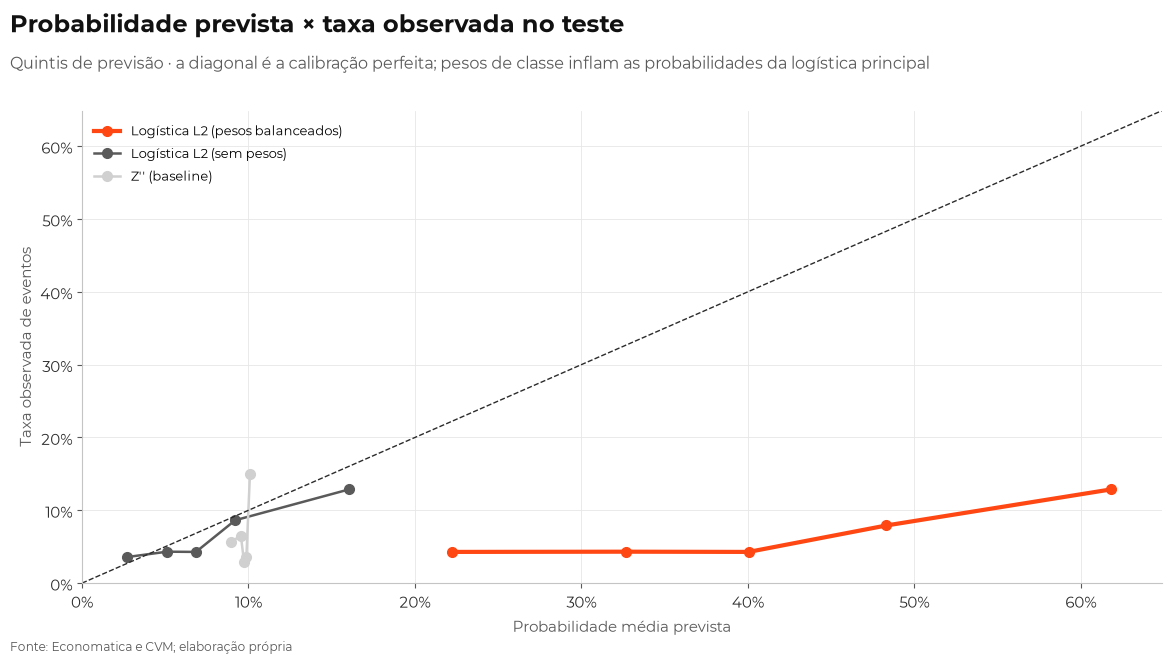

In [21]:
fig, ax = av.fig_calibracao(teste['Y'], {k: prev_te[k] for k in [PRINCIPAL, 'Logística L2 (sem pesos)', "Z'' (baseline)"]}, PRINCIPAL)
style.titulos(fig, 'Probabilidade prevista × taxa observada no teste',
              'Quintis de previsão · a diagonal é a calibração perfeita; pesos de classe inflam as probabilidades da logística principal')
style.salvar(fig, 'fig21_calibracao_teste')
plt.show()

In [22]:
# Previsões do teste para consulta (data/processed não é versionado)
saida = teste[['ticker', 'ano', 'Y']].copy()
for k, v in prev_te.items():
    saida[k] = v
saida.to_csv(cfg.DATA_PROCESSED / 'previsoes_teste.csv', index=False)
saida.sort_values(PRINCIPAL, ascending=False).head(15)

,ticker,ano,Y,Z'' (baseline),Logística L2 (pesos balanceados),Logística L2 (sem pesos),Logística com splines,Gradient boosting (desafiante),Random forest (desafiante)
80,CALI3,2022,0,"0,099","0,805","0,301","0,833","0,733","0,660"
179,CVM15458,2022,0,"0,094","0,783","0,301","0,789","0,807","0,687"
432,MSRO3,2021,0,"0,104","0,771","0,282","0,861","0,740","0,683"
435,MTRE3,2021,0,"0,093","0,769","0,289","0,843","0,769","0,628"
438,MTSA4,2021,0,"0,090","0,769","0,309","0,659","0,625","0,543"
65,BOBR4,2022,0,"0,104","0,764","0,293","0,840","0,761","0,650"
79,CALI3,2021,0,"0,098","0,761","0,249","0,797","0,654","0,627"
297,FRIO3,2021,1,"0,103","0,760","0,266","0,880","0,747","0,620"
419,MMAQ3,2022,0,"0,096","0,747","0,297","0,809","0,754","0,656"
313,GRAO3,2021,0,"0,100","0,746","0,286","0,792","0,830","0,701"


**Leitura.**
- **(i) Contra o acaso e contra o Z'':** a logística principal tem AUC-PR de 0,107, acima da taxa de eventos (0,067), mas **abaixo do Z'' recalibrado** (0,181). A diferença é de −0,075, com intervalo de 90% de −0,19 a −0,003, e `P(> Z'')` = 4%: no topo do ranking, o Z'' é melhor. Nenhum modelo supera o Z'' na AUC-PR. Na AUC-ROC, as árvores ficam à frente: o random forest tem 0,74 contra 0,61 (diferença de +0,12, intervalo de +0,03 a +0,23), e o gradient boosting, 0,71.
- **(ii) Incerteza:** os intervalos são largos (de 0,08 a 0,31 na AUC-PR), como esperado com 47 eventos.
- **(iii) No limiar:** a logística marca 148 de 698 empresas e capta 18 dos 47 distress (38%), com 130 alarmes falsos (precisão de 12%, quase o dobro da taxa-base). O limiar do Z'' marca 692 de 698 e não serve como regra. Nos 20% mais arriscados, a logística capta 38% dos eventos, o Z'' 45% e o random forest 43%.
- **(iv) Calibração:** com pesos de classe, a logística prevê de 22% a 62% por quintil, contra 4% a 13% observados; sem pesos, fica bem mais perto da diagonal. A logística principal deve ser lida como ranking.


## 8. Robustez

Cada linha refaz o pipeline inteiro (escolha de C no treino, ajuste no treino, avaliação no teste) para uma amostra ou especificação alternativa. O que importa é se a **conclusão** (logística contra Z'') se mantém, e não o número exato. Do notebook 03 ainda falta o **painel balanceado**: depende de a dupla definir o que é balanceado aqui.

In [23]:
rob = [mod.avaliar_cenario(amostra, f'principal (alvo {cfg.ALVO_MODELO})'),
       mod.avaliar_cenario(mod.preparar_amostra(ea, cfg.ALVO_ROBUSTEZ),
                           f'alvo {cfg.ALVO_ROBUSTEZ} ({cfg.DEFINICOES_ALVO[cfg.ALVO_ROBUSTEZ][0].upper()})'),
       mod.avaliar_cenario(amostra[~amostra['sem_divida']], 'sem as empresas sem dívida'),
       mod.avaliar_cenario(amostra, 'sem controle de setor', usar_setor=False)]
pd.DataFrame(rob).set_index('cenário')

C:\Users\mitsu\OneDrive\Documentos\GitHub\Projeto-2_CB\src\modelagem.py:262: UserWarning: C escolhido (1000.0) está na borda da grade: estenda cfg.GRADE_C nessa direção.
  warnings.warn(f'C escolhido ({c_esc}) está na borda da grade: estenda cfg.GRADE_C nessa direção.')


C:\Users\mitsu\OneDrive\Documentos\GitHub\Projeto-2_CB\src\modelagem.py:262: UserWarning: C escolhido (1000.0) está na borda da grade: estenda cfg.GRADE_C nessa direção.
  warnings.warn(f'C escolhido ({c_esc}) está na borda da grade: estenda cfg.GRADE_C nessa direção.')


,n treino,eventos treino,n teste,eventos teste,C,AUC-PR logística,AUC-PR Z'',AUC-ROC logística,AUC-ROC Z'',sem informação (AUC-PR)
cenário,,,,,,,,,,
principal (alvo B),1571,151,698,47,"3,000","0,107","0,181","0,639","0,610","0,067"
alvo A (EBIT),1289,188,589,68,"1.000,000","0,155","0,188","0,571","0,608","0,115"
sem as empresas sem dívida,1445,138,656,42,"0,100","0,153","0,186","0,706","0,645","0,064"
sem controle de setor,1571,151,698,47,"1.000,000","0,145","0,181","0,676","0,610","0,067"


**Leitura.** A conclusão se mantém nos quatro cenários: o Z'' fica à frente na AUC-PR em todos, e a logística ganha na AUC-ROC em três (perde com o alvo A). Retirar as empresas sem dívida e retirar o setor **melhoram** a logística no teste (AUC-PR de 0,15 e 0,145, contra 0,107), compatível com a fragilidade da flag e do setor provisório. Essas variantes não viram o modelo principal, porque foram vistas no teste. Com o alvo A (EBIT), o desempenho muda pouco, mas a ordem entre logística e Z'' na AUC-ROC se inverte: o resultado depende um pouco da definição do alvo.


## 9. Conclusões

1. **Hipóteses (seção 5, associação):** só **H1** se confirma de forma robusta: mais alavancagem e mais dívida de curto prazo estão associadas a mais entrada em distress, na logística e no modelo linear. **H4** (FCO/dívida) se confirma no modelo linear, mas não na logística. **H2** (ROA) e **H3** (liquidez) não se confirmam controlando pelas demais, embora separem o risco no bivariado (notebook 03).
2. **Previsão (seção 7):** os indicadores ordenam o risco acima do acaso (AUC-PR de 0,11 contra 0,067), mas **ficam abaixo do Z'' de Altman recalibrado** (0,18) na AUC-PR, com diferença que não cruza zero no intervalo de 90%. As árvores ganham na AUC-ROC (random forest 0,74, gradient boosting 0,71, contra 0,61 do Z''): há sinal de não linearidade, mas que não se traduz no topo do ranking.
3. **Uso prático:** no limiar escolhido, a logística capta 38% dos distress (18 de 47), com 130 alarmes falsos e precisão de 12%. Serve para **ordenar** empresas por risco, não para estimar a probabilidade absoluta.
4. **Limitações:** poucos eventos (intervalos largos); viés de sobrevivência reduzido, mas não eliminado (12 canceladas sem DFP; quem saiu de RJ não aparece como evento); setor provisório; sem controle de tempo (a taxa de eventos varia de 3,6% a 20,5% por ano); alvo baseado na **despesa financeira bruta** do Economatica; árvores com hiperparâmetros fixos.

### Decisões que continuam com a dupla
- **Alvo A ou B** (`cfg.ALVO_MODELO`; hoje B).
- **Controle de tempo**: nenhum, ou Selic/PIB (crie `data/raw/macro/macro_anual.csv` e preencha `cfg.MACRO_COLS`). O notebook 04 prevê a Selic entre os 13 parâmetros, mas a base atual não a traz.
- **Beta do limiar** (`cfg.BETA_LIMIAR`, hoje 2): quanto vale um distress não detectado contra um alarme falso?
- **Painel balanceado** na robustez.
- Trocar o gradient boosting pelo **XGBoost** (já está no `requirements.txt`).
